# Exploratory analysis - telecom churn

Goal: understand the data and decide how to clean and encode it before training the five classifiers.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import config

sns.set_theme(style="whitegrid")
raw = pd.read_csv(config.DATA_PATH)
label = config.TARGET_COL
print(raw.shape)
raw.head()

(5000, 21)


,state,account_length,area_code,phone_number,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,class
0,16,128,415,2845.0,0,1,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,35,107,415,2301.0,0,1,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,31,137,415,1616.0,0,0,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,35,84,408,2510.0,1,0,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,36,75,415,155.0,1,0,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


## 1. Structure and data quality

In [2]:
raw.info()
print("missing cells :", int(raw.isna().sum().sum()))
print("duplicate rows:", int(raw.duplicated().sum()))
print("unique phone_number values:", raw["phone_number"].nunique(), "of", len(raw))

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   state                          5000 non-null   int64  
 1   account_length                 5000 non-null   int64  
 2   area_code                      5000 non-null   int64  
 3   phone_number                   5000 non-null   float64
 4   international_plan             5000 non-null   int64  
 5   voice_mail_plan                5000 non-null   int64  
 6   number_vmail_messages          5000 non-null   int64  
 7   total_day_minutes              5000 non-null   float64
 8   total_day_calls                5000 non-null   int64  
 9   total_day_charge               5000 non-null   float64
 10  total_eve_minutes              5000 non-null   float64
 11  total_eve_calls                5000 non-null   int64  
 12  total_eve_charge               5000 non-null   float64
 13 

In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
state,5000.0,26.00,14.80,0.0,13.00,26.00,39.00,50.00
account_length,5000.0,100.26,39.69,1.0,73.00,100.00,127.00,243.00
area_code,5000.0,436.91,42.21,408.0,408.00,415.00,415.00,510.00
phone_number,5000.0,2499.50,1443.52,0.0,1249.75,2499.50,3749.25,4999.00
international_plan,5000.0,0.09,0.29,0.0,0.00,0.00,0.00,1.00
voice_mail_plan,5000.0,0.26,0.44,0.0,0.00,0.00,1.00,1.00
number_vmail_messages,5000.0,7.76,13.55,0.0,0.00,0.00,17.00,52.00
total_day_minutes,5000.0,180.29,53.89,0.0,143.70,180.10,216.20,351.50
total_day_calls,5000.0,100.03,19.83,0.0,87.00,100.00,113.00,165.00
total_day_charge,5000.0,30.65,9.16,0.0,24.43,30.62,36.75,59.76


## 2. Target balance

class
0    4293
1     707
Name: count, dtype: int64
churn share: 0.1414


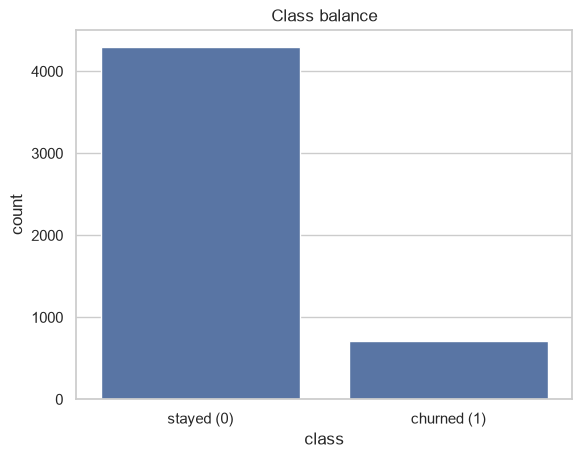

In [4]:
counts = raw[label].value_counts().sort_index()
print(counts)
print("churn share:", round(counts[1] / counts.sum(), 4))

ax = sns.countplot(x=label, data=raw)
ax.set_xticks([0, 1], ["stayed (0)", "churned (1)"])
ax.set_title("Class balance")
plt.show()

## 3. Column types

Several integer columns are really categories (state code, area code, plan flags). Check cardinality to decide.

In [5]:
card = raw.nunique().sort_values()
card.to_frame("unique_values")

,unique_values
class,2
international_plan,2
voice_mail_plan,2
area_code,3
number_customer_service_calls,10
total_intl_calls,21
number_vmail_messages,48
state,51
total_day_calls,123
total_eve_calls,126


In [6]:
cat_cols = ["state", "area_code", "international_plan", "voice_mail_plan"]
drop_cols = ["phone_number"]
num_cols = [c for c in raw.columns if c not in cat_cols + drop_cols + [label]]
print("categorical:", cat_cols)
print("numeric    :", num_cols)

categorical: ['state', 'area_code', 'international_plan', 'voice_mail_plan']
numeric    : ['account_length', 'number_vmail_messages', 'total_day_minutes', 'total_day_calls', 'total_day_charge', 'total_eve_minutes', 'total_eve_calls', 'total_eve_charge', 'total_night_minutes', 'total_night_calls', 'total_night_charge', 'total_intl_minutes', 'total_intl_calls', 'total_intl_charge', 'number_customer_service_calls']


## 4. Churn rate by category

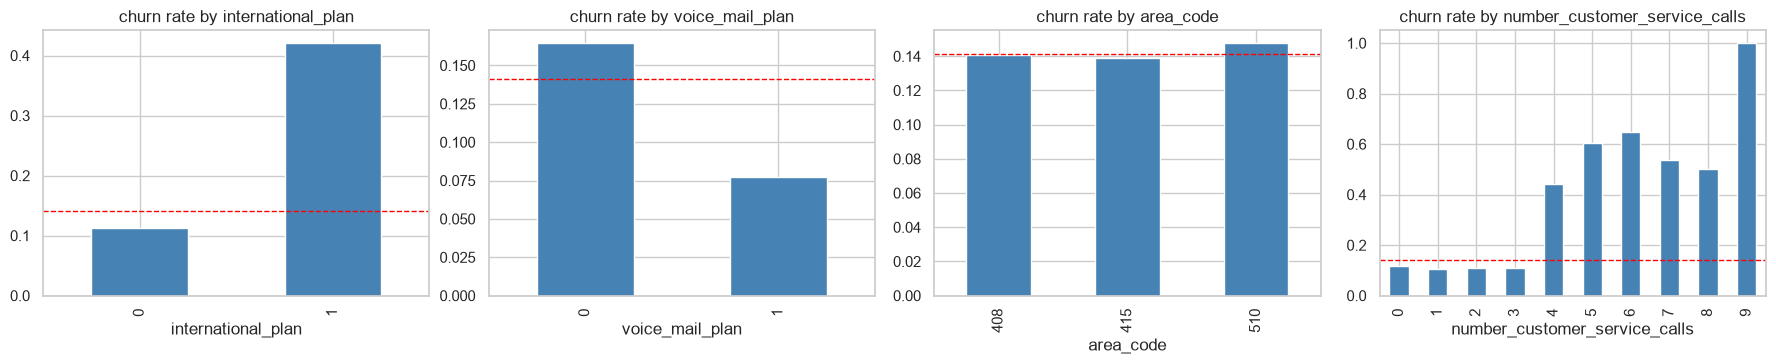

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col in zip(axes, ["international_plan", "voice_mail_plan", "area_code", "number_customer_service_calls"]):
    rate = raw.groupby(col)[label].mean()
    rate.plot.bar(ax=ax, color="steelblue")
    ax.axhline(raw[label].mean(), color="red", ls="--", lw=1)
    ax.set_title(f"churn rate by {col}")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [8]:
state_rate = raw.groupby("state")[label].agg(["mean", "size"]).sort_values("mean", ascending=False)
state_rate.head(8).round(3)

,mean,size
state,,
4,0.269,52
31,0.250,112
47,0.245,98
43,0.224,116
26,0.212,99
20,0.206,102
33,0.189,90
21,0.184,103


## 5. Numeric features vs. churn

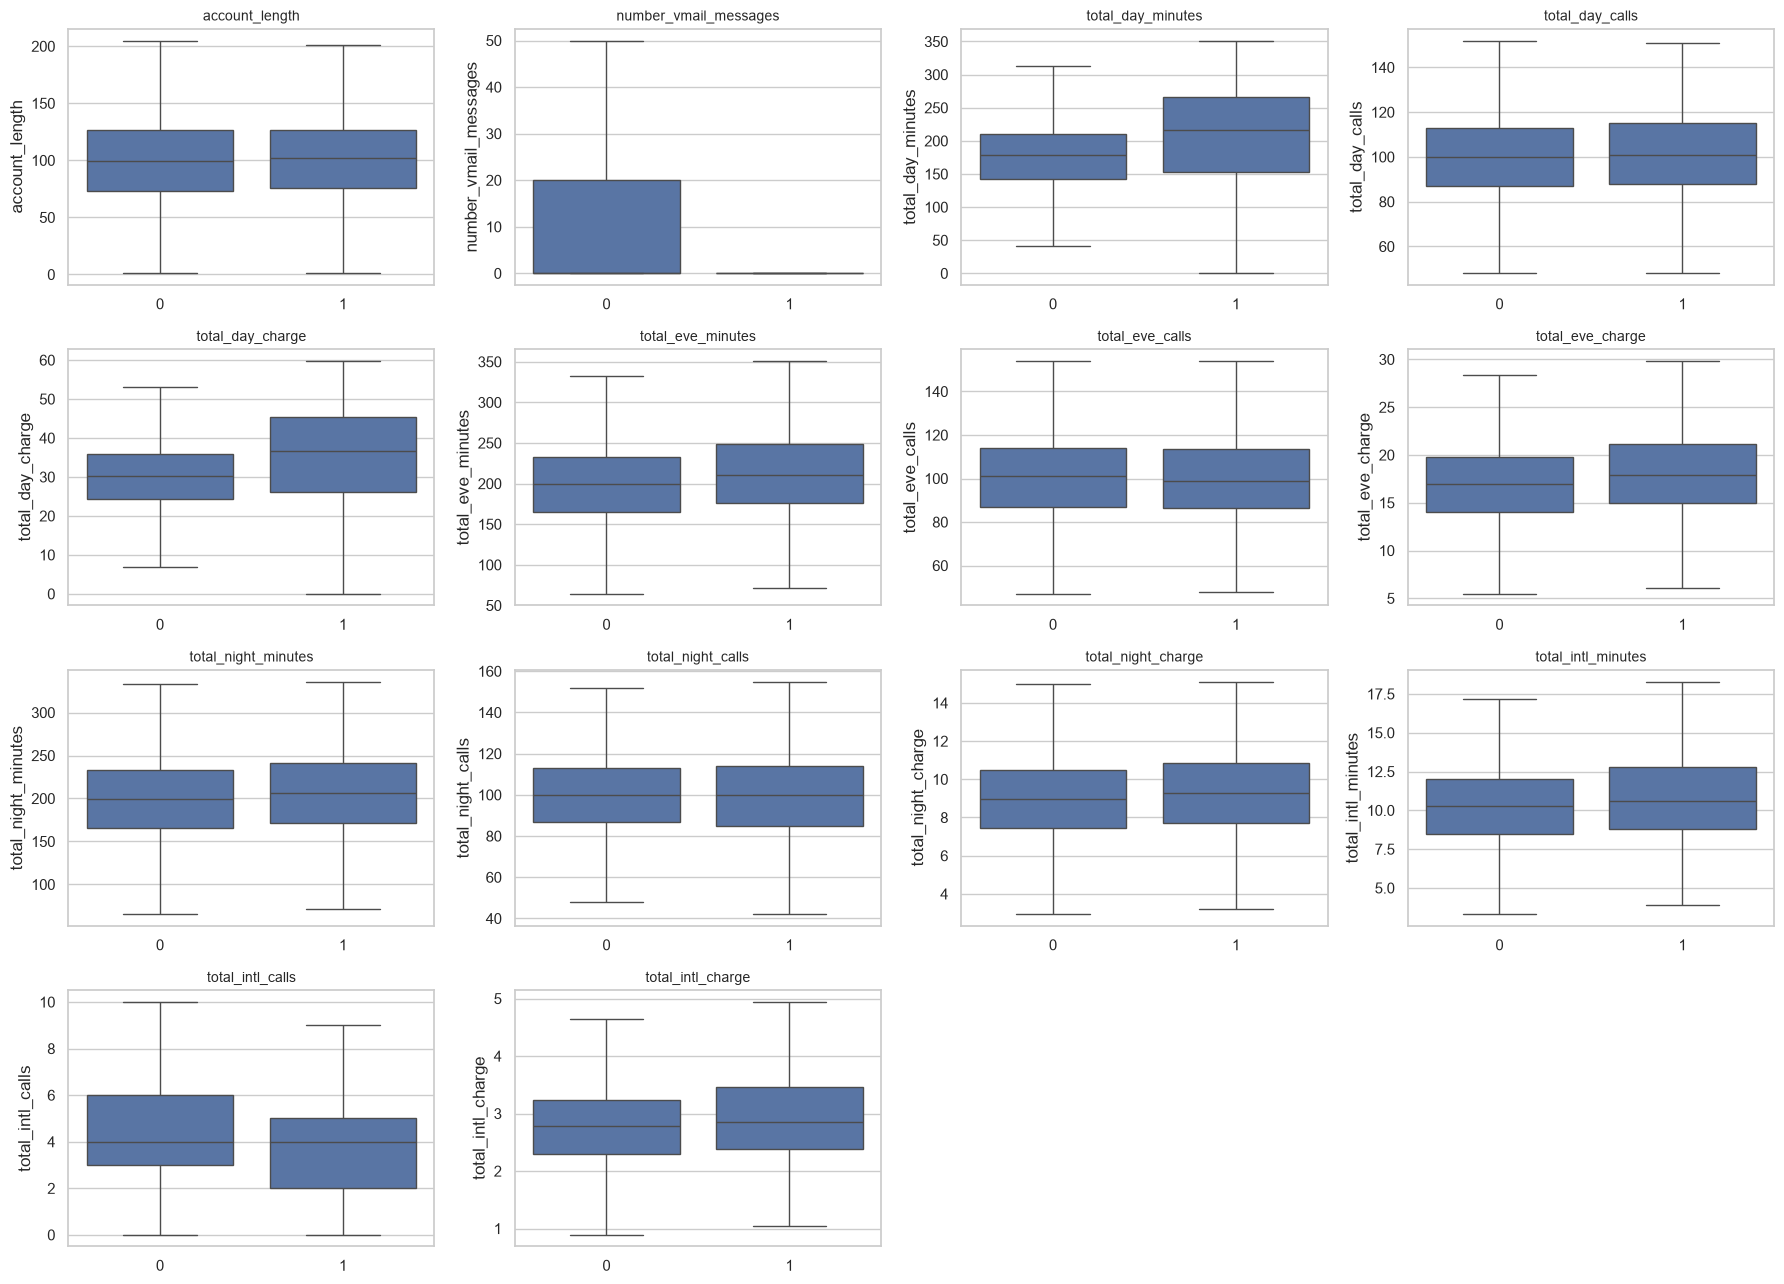

In [9]:
plot_cols = [c for c in num_cols if c != "number_customer_service_calls"]
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
for ax, col in zip(axes.ravel(), plot_cols):
    sns.boxplot(x=label, y=col, data=raw, ax=ax, showfliers=False)
    ax.set_xlabel("")
    ax.set_title(col, fontsize=10)
for ax in axes.ravel()[len(plot_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
raw.groupby(label)[num_cols].mean().T.round(2)

class,0,1
account_length,99.92,102.33
number_vmail_messages,8.29,4.50
total_day_minutes,175.75,207.87
total_day_calls,99.90,100.82
total_day_charge,29.88,35.34
total_eve_minutes,198.81,211.76
total_eve_calls,100.24,99.88
total_eve_charge,16.90,18.00
total_night_minutes,199.46,206.08
total_night_calls,99.98,99.58


## 6. Correlations and redundancy

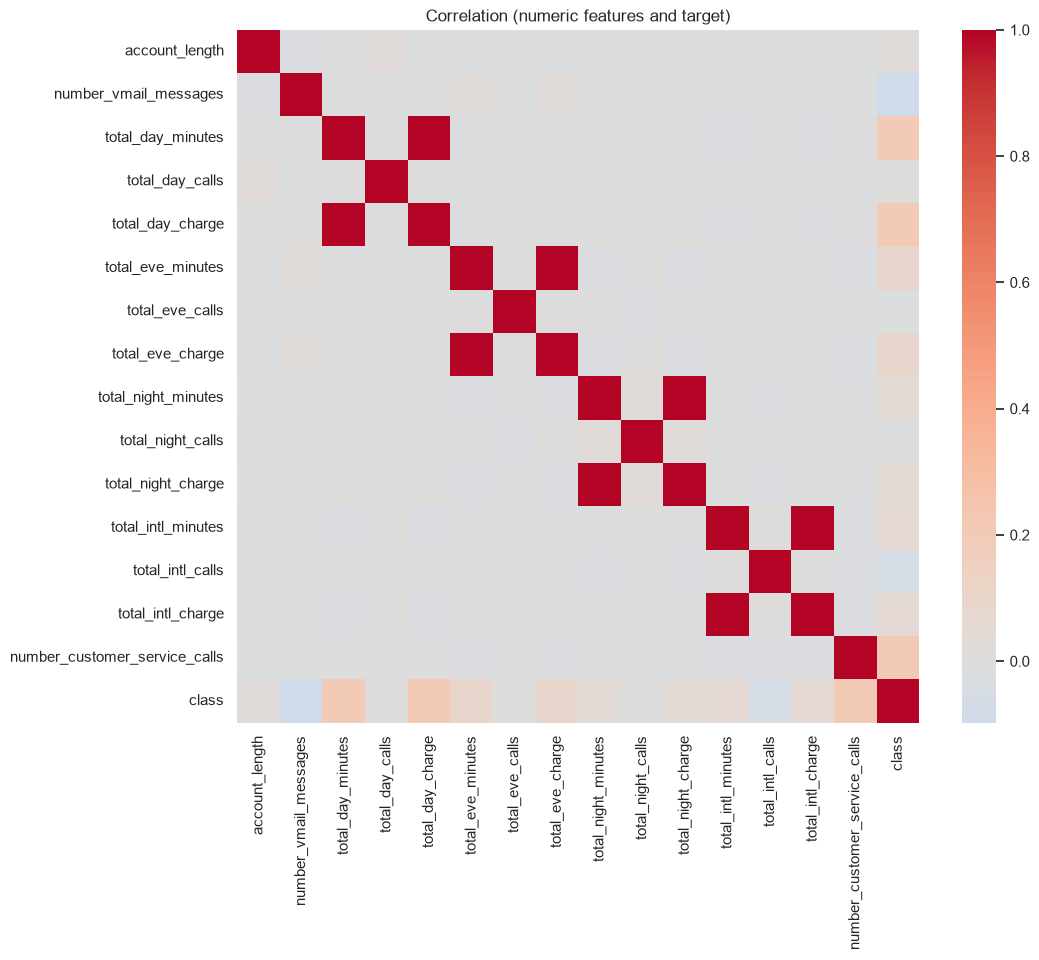

number_customer_service_calls    0.213
total_day_minutes                0.208
total_day_charge                 0.208
number_vmail_messages           -0.098
total_eve_minutes                0.089
total_eve_charge                 0.089
total_intl_minutes               0.063
total_intl_charge                0.063
Name: class, dtype: float64


In [11]:
corr = raw[num_cols + [label]].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation (numeric features and target)")
plt.show()

print(corr[label].drop(label).sort_values(key=abs, ascending=False).head(8).round(3))

In [12]:
pairs = [("total_day_minutes", "total_day_charge"), ("total_eve_minutes", "total_eve_charge"),
         ("total_night_minutes", "total_night_charge"), ("total_intl_minutes", "total_intl_charge")]
for a, b in pairs:
    print(f"{a} vs {b}: r = {raw[a].corr(raw[b]):.4f}")

total_day_minutes vs total_day_charge: r = 1.0000
total_eve_minutes vs total_eve_charge: r = 1.0000
total_night_minutes vs total_night_charge: r = 1.0000
total_intl_minutes vs total_intl_charge: r = 1.0000


## 7. Findings and preprocessing decisions

- Data quality: 5,000 rows, no missing values, no duplicates; `phone_number` is unique per row (an identifier).
- Imbalance: about 14.1% churn (707 of 5,000), so always predicting "stayed" already gives about 86% accuracy.
- Strongest signals: international plan (42% churn vs 11% without), 4 or more customer service calls (44-65% churn vs about 11%), higher daytime usage (r about 0.21), no voice mail plan (16.5% vs 7.7%). Area code carries almost no signal; churn varies by state (5% to 27%) but with small groups.
- Redundant features: each `*_charge` column is perfectly correlated with its `*_minutes` column (r = 1.0), so one of each pair adds nothing for linear models and Naive Bayes.
- Decisions: drop `phone_number`; one-hot encode categorical columns; scale numeric columns; stratified split; judge models on AUC / F1 / MCC rather than accuracy alone.